<a href="https://colab.research.google.com/github/samodamarasinghe/CRM_CW1/blob/main/CRM_CW1_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install once in Colab (skip if your environment already has these).
%pip -q install yfinance pandas numpy scipy scikit-learn matplotlib pyarrow lxml beautifulsoup4 requests openpyxl

In [ ]:
import sys, json, time, hashlib, warnings, platform
from io import StringIO
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yfinance as yf
import scipy
import sklearn
import matplotlib.pyplot as plt
import requests
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from IPython.display import display

In [ ]:
OUTPUT = Path('CWK1_outputs')
FIGS = OUTPUT / 'figures'
OUTPUT.mkdir(exist_ok=True); FIGS.mkdir(exist_ok=True)
START, END = '2021-01-01', '2025-01-01'  # END exclusive
RUN_UTC = datetime.now(timezone.utc).isoformat()
OBS_START = pd.Timestamp(START)
OBS_END = pd.Timestamp(END)
SEED = 42
# Thresholds are transparent analysis choices; justify them in your report.
MIN_WEEKLY_COVERAGE = 0.90
MIN_LAST_SESSIONS = 80   # 20 for history + last 60 for RFM
BATCH_SIZE = 20
USE_CACHED_SNAPSHOT = False   # Change to True when re-running a saved historical snapshot
print('Run UTC:', RUN_UTC)
print('Versions:', {'python': platform.python_version(), 'pandas': pd.__version__,
                    'numpy': np.__version__, 'yfinance': yf.__version__,
                    'scipy': scipy.__version__, 'sklearn': sklearn.__version__})

Run UTC: 2026-11-23T05:57:29.055220+00:00
Versions: {'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'scipy': '1.16.3', 'sklearn': '1.6.1'}


1.1 — Ticker selection and data acquisition

In [ ]:
WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
const_path = OUTPUT / 'constituents.csv'
if USE_CACHED_SNAPSHOT and const_path.exists():
    constituents = pd.read_csv(const_path)
else:
    response = requests.get(WIKI_URL, headers={'User-Agent': 'Mozilla/5.0 (educational research)'}, timeout=40)
    response.raise_for_status()
    tables = pd.read_html(StringIO(response.text))
    candidates = [t for t in tables if {'Symbol', 'GICS Sector'}.issubset(set(t.columns))]
    if not candidates:
        raise ValueError('Wikipedia table layout changed; inspect columns and choose the S&P 500 table.')
    constituents = candidates[0].copy()
    constituents['YahooTicker'] = constituents['Symbol'].astype(str).str.replace('.', '-', regex=False)
    constituents['RetrievalUTC'] = RUN_UTC
    constituents = constituents.drop_duplicates('YahooTicker')
    constituents.to_csv(const_path, index=False)

In [ ]:
assert {'YahooTicker', 'GICS Sector'}.issubset(constituents.columns)
TICKERS = constituents['YahooTicker'].dropna().astype(str).unique().tolist()
ALL_TICKERS = TICKERS + ['^GSPC']
print('Current constituents downloaded:', len(TICKERS), '| Benchmark: ^GSPC')
display(constituents[['Symbol', 'YahooTicker', 'Security', 'GICS Sector']].head())

Current constituents downloaded: 503 | Benchmark: ^GSPC


,Symbol,YahooTicker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


In [ ]:
def standardize_yahoo_batch(download, tickers):
    """Convert yfinance 'group_by=ticker' output into one long-format data snapshot."""
    if download is None or download.empty:
        return pd.DataFrame(), list(tickers)
    records, missing = [], []
    for ticker in tickers:
        if isinstance(download.columns, pd.MultiIndex):
            if ticker in download.columns.get_level_values(0):
                one = download[ticker].copy()
            elif ticker in download.columns.get_level_values(1):
                one = download.xs(ticker, axis=1, level=1).copy()
            else:
                missing.append(ticker); continue
        else:
            if len(tickers) != 1:
                missing.append(ticker); continue
            one = download.copy()
        if not {'Close','Volume'}.issubset(one.columns):
            missing.append(ticker); continue
        # yfinance sometimes returns named columns with all NaNs for a failed symbol.
        if one[['Close','Volume']].notna().sum().sum() == 0:
            missing.append(ticker); continue
        one = one.reset_index()
        date_col = 'Date' if 'Date' in one.columns else one.columns[0]
        one = one.rename(columns={date_col: 'Date'})
        one['Date'] = pd.to_datetime(one['Date'], utc=True).dt.tz_convert(None).dt.normalize()
        for col in ['Adj Close','Dividends','Stock Splits']:
            if col not in one.columns:
                one[col] = np.nan if col == 'Adj Close' else 0.0
        one['Ticker'] = ticker
        records.append(one[['Date','Ticker','Close','Adj Close','Volume','Dividends','Stock Splits']])
    return (pd.concat(records, ignore_index=True) if records else pd.DataFrame()), missing

In [ ]:
def download_chunk(tickers, retries=3):
    last_error = None
    for attempt in range(retries):
        try:
            raw = yf.download(tickers=tickers, start=START, end=END, interval='1d',
                              auto_adjust=False, actions=True, group_by='ticker',
                              multi_level_index=True, progress=False,
                              threads=False, timeout=40)
            result, missing = standardize_yahoo_batch(raw, tickers)
            if not result.empty:
                return result, missing, None
            last_error = 'Empty response'
        except Exception as exc:
            last_error = repr(exc)
        time.sleep(2 * (attempt + 1))
    return pd.DataFrame(), list(tickers), last_error

raw_path = OUTPUT / 'daily_snapshot.parquet'
log_path = OUTPUT / 'download_log.csv'
if USE_CACHED_SNAPSHOT and raw_path.exists() and log_path.exists():
    raw_daily = pd.read_parquet(raw_path)
    download_log = pd.read_csv(log_path)
else:
    batches, failures = [], []
    for i in range(0, len(ALL_TICKERS), BATCH_SIZE):
        tickers_batch = ALL_TICKERS[i:i+BATCH_SIZE]
        part, missing, error = download_chunk(tickers_batch)
        if not part.empty:
            batches.append(part)
        for t in missing:
            failures.append({'Ticker':t, 'BatchNumber':i//BATCH_SIZE+1,
                             'Reason': error or 'Missing/empty ticker payload'})
        print(f'Batch {1+i//BATCH_SIZE}: requested {len(tickers_batch)}, missing {len(missing)}')
        time.sleep(1)
    raw_daily = pd.concat(batches, ignore_index=True) if batches else pd.DataFrame()
    download_log = pd.DataFrame(failures, columns=['Ticker','BatchNumber','Reason'])
    if raw_daily.empty or '^GSPC' not in raw_daily['Ticker'].values:
        raise RuntimeError('No usable benchmark: check download errors or load a documented cache.')
    raw_daily.to_parquet(raw_path, index=False)
    download_log.to_csv(log_path, index=False)


Batch 1: requested 20, missing 0
Batch 2: requested 20, missing 0
Batch 3: requested 20, missing 0
Batch 4: requested 20, missing 0
Batch 5: requested 20, missing 0
Batch 6: requested 20, missing 0
Batch 7: requested 20, missing 0
Batch 8: requested 20, missing 0
Batch 9: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 10: requested 20, missing 1
Batch 11: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 12: requested 20, missing 1
Batch 13: requested 20, missing 0
Batch 14: requested 20, missing 0
Batch 15: requested 20, missing 0
Batch 16: requested 20, missing 0
Batch 17: requested 20, missing 0
Batch 18: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 19: requested 20, missing 1
Batch 20: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 21: requested 20, missing 1
Batch 22: requested 20, missing 0
Batch 23: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 24: requested 20, missing 1
Batch 25: requested 20, missing 0
Batch 26: requested 4, missing 0


In [ ]:
print('Rows:', len(raw_daily), '| tickers with any records:', raw_daily.Ticker.nunique())
print('Failed/missing tickers:', download_log.Ticker.nunique())
display(download_log.head())

Rows: 501495 | tickers with any records: 499
Failed/missing tickers: 5


,Ticker,BatchNumber,Reason
0,FDXF,10,Missing/empty ticker payload
1,HONA,12,Missing/empty ticker payload
2,Q,19,Missing/empty ticker payload
3,SNDK,21,Missing/empty ticker payload
4,VYLR,24,Missing/empty ticker payload


1.2 — Data validation and alignment

In [ ]:
raw_daily['Date'] = pd.to_datetime(raw_daily['Date']).dt.normalize()
raw_daily = raw_daily.sort_values(['Ticker','Date']).copy()
dup_mask = raw_daily.duplicated(['Ticker','Date'], keep=False)
duplicate_evidence = raw_daily.loc[dup_mask].copy()
duplicate_evidence.to_csv(OUTPUT/'duplicate_date_evidence.csv',index=False)
# Only *identical* duplicate records are removed; conflicting records cause exclusion.
conflicts = set()
if len(duplicate_evidence):
    for ticker, part in duplicate_evidence.groupby('Ticker'):
        differing = part.groupby('Date')[['Close','Adj Close','Volume']].nunique(dropna=False).gt(1).any(axis=1)
        if differing.any(): conflicts.add(ticker)
    raw_daily = raw_daily.drop_duplicates(keep='first')
raw_daily = raw_daily.drop_duplicates(['Ticker','Date'], keep='first')
raw_daily[['Close','Adj Close','Volume']] = raw_daily[['Close','Adj Close','Volume']].apply(pd.to_numeric,errors='coerce')
raw_daily['BadClose'] = raw_daily['Close'].isna() | (raw_daily['Close']<=0)
raw_daily['BadAdj'] = raw_daily['Adj Close'].isna() | (raw_daily['Adj Close']<=0)
raw_daily['BadVolume'] = raw_daily['Volume'].isna() | (raw_daily['Volume']<=0)
raw_daily['AdjustmentRatio'] = raw_daily['Adj Close']/raw_daily['Close']
raw_daily['AdjustmentChange'] = raw_daily.groupby('Ticker')['AdjustmentRatio'].pct_change(fill_method=None).abs()
raw_daily['CorporateActionReviewFlag'] = (raw_daily['AdjustmentChange']>0.10) | (raw_daily['Stock Splits'].fillna(0)!=0)

In [ ]:
validation_summary = raw_daily.groupby('Ticker').agg(
    DailyRows=('Date','size'), FirstDate=('Date','min'), LastDate=('Date','max'),
    MissingClose=('BadClose','sum'), MissingAdj=('BadAdj','sum'),
    ZeroOrMissingVolume=('BadVolume','sum'), CorporateActionFlags=('CorporateActionReviewFlag','sum'))
validation_summary.to_csv(OUTPUT/'validation_summary.csv')
# An explicit table of anomalous days to inspect before drawing conclusions.
raw_daily.loc[raw_daily['BadClose']|raw_daily['BadAdj']|raw_daily['BadVolume']|
              raw_daily['CorporateActionReviewFlag'],
              ['Ticker','Date','Close','Adj Close','Volume','AdjustmentRatio','Stock Splits',
               'BadClose','BadAdj','BadVolume','CorporateActionReviewFlag']].to_csv(
                   OUTPUT/'daily_validation_flags.csv',index=False)
display(validation_summary.describe(include='all'))
print('Conflicting duplicate tickers:', sorted(conflicts)[:20], 'count=',len(conflicts))

,DailyRows,FirstDate,LastDate,MissingClose,MissingAdj,ZeroOrMissingVolume,CorporateActionFlags
count,499.0,499,499,499.000000,499.000000,499.000000,499.000000
mean,1005.0,2021-01-04 00:00:00.000000256,2024-12-31 00:00:00,8.388778,8.388778,9.294589,0.122244
min,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
25%,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
50%,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
75%,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
max,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,812.000000,812.000000,812.000000,3.000000
std,0.0,NaN,NaN,74.387682,74.387682,76.680761,0.379026


Conflicting duplicate tickers: [] count= 0


In [ ]:
# Pivot without any forward/backward filling.
clean_adj = raw_daily['Adj Close'].where(~raw_daily['BadAdj'])
clean_close = raw_daily['Close'].where(~raw_daily['BadClose'])
clean_vol = raw_daily['Volume'].where(~raw_daily['BadVolume'])
working = raw_daily.assign(ValidAdj=clean_adj, ValidClose=clean_close, ValidVolume=clean_vol)
P_ADJ = working.pivot(index='Date',columns='Ticker',values='ValidAdj').sort_index()
P_CLOSE = working.pivot(index='Date',columns='Ticker',values='ValidClose').sort_index()
P_VOL = working.pivot(index='Date',columns='Ticker',values='ValidVolume').sort_index()
if '^GSPC' not in P_ADJ.columns:
    raise RuntimeError('Missing ^GSPC adjusted closing prices')
market_dates = pd.DatetimeIndex(P_ADJ['^GSPC'].dropna().index).sort_values()
if len(market_dates)<200:
    raise RuntimeError('Benchmark history too short; investigate source/cached data')
P_ADJ = P_ADJ.reindex(market_dates)
P_CLOSE = P_CLOSE.reindex(market_dates)
P_VOL = P_VOL.reindex(market_dates)
OBSERVATION_DATE = market_dates.max()  # common cutoff; shares must have valid data here
print('Benchmark sessions:',len(market_dates),'| last common potential observation date:',OBSERVATION_DATE.date())

Benchmark sessions: 1005 | last common potential observation date: 2024-12-31


1.3.1 — Mean weekly return

In [ ]:
WEEKLY_PRICES = P_ADJ.resample('W-FRI').last()
week_starts = WEEKLY_PRICES.index - pd.Timedelta(days=4)
full_week = (week_starts >= OBS_START) & (WEEKLY_PRICES.index < OBS_END)
WEEKLY_PRICES = WEEKLY_PRICES.loc[full_week]
WEEKLY_RETURNS = WEEKLY_PRICES.pct_change(fill_method=None)
BENCHMARK_RETURNS = WEEKLY_RETURNS['^GSPC'].dropna()
WEEKLY_RETURNS.to_csv(OUTPUT/'weekly_returns.csv',index_label='WeekEndingFriday')
print('Calendar weeks:',len(WEEKLY_PRICES),'| benchmark return weeks:',len(BENCHMARK_RETURNS))
assert (WEEKLY_RETURNS.index.dayofweek == 4).all(), 'Week labels must be Fridays'
# Boundary safety: a missing intermediate week does not generate a multiweek return.
assert pd.Series([100., np.nan, 121.]).pct_change(fill_method=None).isna().iloc[2]

Calendar weeks: 208 | benchmark return weeks: 207


1.3.2 — Weekly beta

In [ ]:

records=[]
bench_weeks = len(BENCHMARK_RETURNS)

for ticker in TICKERS:
    if ticker not in WEEKLY_RETURNS:
        records.append({
            'Ticker':ticker,
            'MeanWeeklyReturn':np.nan,
            'WeeklyBeta':np.nan,
            'AlignedWeeks':0
        })
        continue

    aligned = pd.concat({
        'Share':WEEKLY_RETURNS[ticker],
        'Benchmark':WEEKLY_RETURNS['^GSPC']
    },axis=1).dropna()

    var = aligned['Benchmark'].var() if len(aligned)>1 else np.nan

    records.append({
        'Ticker':ticker,
        'MeanWeeklyReturn':aligned['Share'].mean() if len(aligned) else np.nan,
        'WeeklyBeta':aligned['Share'].cov(aligned['Benchmark'])/var
            if pd.notna(var) and var>0 else np.nan,
        'AlignedWeeks':len(aligned)
    })

RISK_ALL = pd.DataFrame(records).set_index('Ticker')
RISK_ALL.to_csv(OUTPUT/'risk_return_features_all.csv')

display(RISK_ALL.sort_values('AlignedWeeks',ascending=False).head())


,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
Ticker,,,
ZTS,0.000763,0.979783,207
MMM,0.001142,0.869079,207
AOS,0.001991,1.042804,207
ABT,0.000971,0.583544,207
ABBV,0.003749,0.425366,207


1.4.1 — Recency

In [ ]:
# Latest 60 trading sessions and observation date
last60 = P_VOL.index[-60:]
obs_date = last60[-1]

# High-volume day: Volume > 2 × previous 20-day average
previous20 = P_VOL.shift(1).rolling(20, min_periods=20).mean()
high_volume = P_VOL > (2 * previous20)

# Find the last high-volume event for each share
last_event_date = high_volume.apply(
    lambda x: x.index[x].max() if x.any() else pd.NaT
)
last_event_date = pd.to_datetime(last_event_date)

# Recency in calendar days
recency = (obs_date - last_event_date).dt.days

print("Shares with no high-volume event:",
      recency[recency.isna()].index.tolist()[:10], "..." if len(recency[recency.isna()]) > 10 else "")

print(recency.describe())

Shares with no high-volume event: [] 
count    499.000000
mean      20.673347
std       21.537571
min        4.000000
25%       11.000000
50%       11.000000
75%       18.000000
max      222.000000
dtype: float64


1.4.2 — Frequency

In [ ]:
# Number of high-volume DAYS in the latest 60 sessions
frequency = high_volume.loc[last60].sum()

print(frequency.describe())


count    499.000000
mean       2.997996
std        1.333081
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
dtype: float64


1.4.3 — Monetary

In [ ]:
# Total estimated traded value over the latest 60 sessions
monetary = (P_CLOSE * P_VOL).loc[last60].sum(min_count=60)

print(monetary.describe())

count    4.990000e+02
mean     2.860331e+12
std      6.301019e+13
min      1.297483e+09
25%      1.025172e+10
50%      1.688430e+10
75%      3.308534e+10
max      1.407578e+15
dtype: float64


In [ ]:
rfm = pd.DataFrame({
    'Last_Event_Date': last_event_date,
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})

print(rfm.describe())


                     Last_Event_Date     Recency   Frequency      Monetary
count                            499  499.000000  499.000000  4.990000e+02
mean   2024-12-10 07:50:22.845691392   20.673347    2.997996  2.860331e+12
min              2024-05-23 00:00:00    4.000000    0.000000  1.297483e+09
25%              2024-12-13 00:00:00   11.000000    2.000000  1.025172e+10
50%              2024-12-20 00:00:00   11.000000    3.000000  1.688430e+10
75%              2024-12-20 00:00:00   18.000000    4.000000  3.308534e+10
max              2024-12-27 00:00:00  222.000000    8.000000  1.407578e+15
std                              NaN   21.537571    1.333081  6.301019e+13


1.5 — Metric interpretation, logs and evidence

In [ ]:
# to fix the NameErrors and KeyErrors
import numpy as np
import pandas as pd

In [ ]:
# Create RFM_BASE from the already calculated 'rfm' DataFrame
RFM_BASE = pd.DataFrame(index=TICKERS)
RFM_BASE['R'] = recency.reindex(TICKERS)
RFM_BASE['F'] = frequency.reindex(TICKERS)
RFM_BASE['M'] = monetary.reindex(TICKERS)


In [ ]:
# Set HasLast80 to True only if the ticker successfully exists in our clean price tables
valid_tickers_set = set(P_CLOSE.columns)
RFM_BASE['HasLast80'] = [t in valid_tickers_set for t in TICKERS]
RFM_BASE['LastEvent'] = last_event_date.reindex(TICKERS)
RFM_BASE['RFMReason'] = RFM_BASE['HasLast80'].map({True: 'Included', False: 'Excluded (Missing Price Data)'})

In [ ]:
# Recreate threshold and flag matrices for the worked-example assert tests
PREVIOUS20_MEAN = previous20
THRESHOLD = 2 * PREVIOUS20_MEAN
EVENT_FLAGS = high_volume

for ticker in TICKERS:
    if bool(RFM_BASE.loc[ticker, 'HasLast80']) and ticker in valid_tickers_set:
        close60 = P_CLOSE.loc[last60, ticker]
        volume60 = P_VOL.loc[last60, ticker]
        monetary[ticker] = float((close60 * volume60).sum())
    else:
        monetary[ticker] = np.nan

RFM_BASE['M'] = pd.Series(monetary)

RFM_ALL = RFM_BASE[
    ['R', 'F', 'M', 'HasLast80', 'LastEvent', 'RFMReason']
].copy()

RFM_ALL.to_csv(OUTPUT / 'rfm_features_all.csv')

In [ ]:
# Worked-example evidence
sample_ticker = (
    'AAPL' if 'AAPL' in P_VOL.columns else TICKERS[0]
)

example_events = pd.DataFrame({
    'Date': market_dates,
    'Close': P_CLOSE[sample_ticker].values,
    'Volume': P_VOL[sample_ticker].values,
    'Prior20Mean': PREVIOUS20_MEAN[sample_ticker].values,
    'Threshold2x': THRESHOLD[sample_ticker].values,
    'Qualifies': EVENT_FLAGS[sample_ticker].values
})

example_events['EstTradedValue'] = (
    example_events['Close'] * example_events['Volume']
)

example_60 = example_events.set_index('Date').loc[last60]

example_60.to_csv(
    OUTPUT / f'{sample_ticker}_last60_calculations.csv'
)
example_events.to_csv(
    OUTPUT / f'{sample_ticker}_event_evidence.csv',
    index=False
)

if bool(RFM_ALL.loc[sample_ticker, 'HasLast80']):
    assert int(example_60['Qualifies'].sum()) == int(
        RFM_ALL.loc[sample_ticker, 'F']
    )

    assert np.isclose(
        example_60['EstTradedValue'].sum(),
        RFM_ALL.loc[sample_ticker, 'M']
    )

    event_dates = example_events.loc[
        example_events['Qualifies'], 'Date'
    ]

    expected_recency = (
        (OBSERVATION_DATE - event_dates.max()).days
        if not event_dates.empty else np.nan
    )

    assert (
        (pd.isna(expected_recency) and
         pd.isna(RFM_ALL.loc[sample_ticker, 'R']))
        or expected_recency == RFM_ALL.loc[sample_ticker, 'R']
    )

print('Observation date:', OBSERVATION_DATE.date())
print(
    'Final 60-session window:',
    last60[0].date(), 'to', last60[-1].date()
)
print('Worked-example ticker:', sample_ticker)

display(RFM_ALL.loc[[sample_ticker]])
display(example_60.tail(10))

Observation date: 2024-12-31
Final 60-session window: 2024-10-07 to 2024-12-31
Worked-example ticker: AAPL


,R,F,M,HasLast80,LastEvent,RFMReason
AAPL,11.0,2.0,6.233034e+11,True,2024-12-20,Included


,Close,Volume,Prior20Mean,Threshold2x,Qualifies,EstTradedValue
Date,,,,,,
2024-12-17,253.479996,51356400.0,42354720.0,84709440.0,False,1.301782e+10
2024-12-18,248.050003,56774100.0,42690855.0,85381710.0,False,1.408282e+10
2024-12-19,249.789993,60882300.0,43718970.0,87437940.0,False,1.520779e+10
2024-12-20,254.490005,147495300.0,45004605.0,90009210.0,True,3.753608e+10
2024-12-23,255.270004,40858800.0,50273955.0,100547910.0,False,1.043003e+10
2024-12-24,258.200012,23234700.0,50408480.0,100816960.0,False,5.999200e+09
2024-12-26,259.019989,27237100.0,47062575.0,94125150.0,False,7.054953e+09
2024-12-27,255.589996,42355300.0,46125120.0,92250240.0,False,1.082559e+10
2024-12-30,252.199997,35557500.0,46567965.0,93135930.0,False,8.967601e+09


In [ ]:
EXCLUSIONS=[]
for ticker in TICKERS:
    reasons=[]
    if ticker in conflicts: reasons.append('Conflicting duplicate daily data')
    r=RISK_ALL.loc[ticker]; f=RFM_ALL.loc[ticker]
    if not np.isfinite(r['MeanWeeklyReturn']) or not np.isfinite(r['WeeklyBeta']):
        reasons.append('Weekly return / beta unavailable')

    # Calculate WeeklyCoverage on the fly since it's not a column in RISK_ALL
    weekly_coverage = r['AlignedWeeks'] / bench_weeks if bench_weeks > 0 else 0.0
    if weekly_coverage < MIN_WEEKLY_COVERAGE:
        reasons.append(f"Weekly coverage {weekly_coverage:.1%} < {MIN_WEEKLY_COVERAGE:.0%}")

    if not bool(f['HasLast80']): reasons.append('Missing final 80-session RFM history')
    if pd.isna(f['R']): reasons.append('No valid R event / RFM excluded')
    if pd.isna(f['M']) or (pd.notna(f['M']) and f['M']<0): reasons.append('Invalid M')
    EXCLUSIONS.append({'Ticker':ticker,'Included':not bool(reasons),
                       'Reasons':'; '.join(dict.fromkeys(reasons)) or 'Included'})
EXCLUSION_LOG = pd.DataFrame(EXCLUSIONS).set_index('Ticker')
EXCLUSION_LOG.to_csv(OUTPUT/'share_exclusion_log.csv')
COMMON = EXCLUSION_LOG.index[EXCLUSION_LOG.Included].tolist()
if len(COMMON)<10:
    raise ValueError('Fewer than ten shared stocks passed validation; inspect exclusions before clustering')
SHARE_FEATURES = RISK_ALL[['MeanWeeklyReturn','WeeklyBeta']].join(RFM_ALL[['R','F','M']],how='inner').loc[COMMON].copy()
sector_map = constituents.set_index('YahooTicker')['GICS Sector']
SHARE_FEATURES['Sector'] = sector_map.reindex(SHARE_FEATURES.index)
SHARE_FEATURES.to_csv(OUTPUT/'share_feature_table.csv',index_label='Ticker')
print('Common eligible shares:',len(COMMON),'out of',len(TICKERS))
display(EXCLUSION_LOG['Reasons'].value_counts().head(12))
display(SHARE_FEATURES[['MeanWeeklyReturn','WeeklyBeta','R','F','M']].describe().T)

Common eligible shares: 491 out of 503


,count
Reasons,
Included,491
Weekly return / beta unavailable; Weekly coverage 0.0% < 90%; Missing final 80-session RFM history; No valid R event / RFM excluded; Invalid M,5
Weekly coverage 18.8% < 90%,2
Weekly coverage 73.9% < 90%,1
Weekly coverage 51.2% < 90%,1
Weekly coverage 19.3% < 90%,1
Weekly coverage 86.0% < 90%,1
Weekly coverage 30.9% < 90%,1


,count,mean,std,min,25%,50%,75%,max
MeanWeeklyReturn,491.0,2.895440e-03,2.698619e-03,-4.468093e-03,1.196842e-03,2.665346e-03,4.234419e-03,1.777248e-02
WeeklyBeta,491.0,9.807129e-01,4.207479e-01,5.545273e-02,6.689163e-01,9.531760e-01,1.180579e+00,3.778560e+00
R,491.0,2.043381e+01,2.128392e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.650000e+01,2.220000e+02
F,491.0,2.993890e+00,1.328634e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,491.0,3.973205e+10,1.287707e+11,1.297483e+09,1.025172e+10,1.670905e+10,3.242874e+10,1.847697e+12


Task 2 — Stock Segmentation and Sensitivity Analysis

2.1 — Feature Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

In [ ]:
# Combine Task 1 risk-return and RFM results
features = RISK_ALL[
    ['MeanWeeklyReturn', 'WeeklyBeta']
].rename(columns={
    'MeanWeeklyReturn': 'Mean_Weekly_Return',
    'WeeklyBeta': 'Beta'
}).join(
    rfm[['Recency', 'Frequency', 'Monetary']],
    how='inner'
)

In [ ]:
# Use the same eligible shares for both analyses
if 'COMMON' in globals():
    features = features.reindex(COMMON)

features = features.replace(
    [np.inf, -np.inf], np.nan
).dropna()

features = features[
    (features[['Recency', 'Frequency', 'Monetary']] >= 0).all(axis=1)
].copy()

raw_cols = [
    'Mean_Weekly_Return', 'Beta',
    'Recency', 'Frequency', 'Monetary'
]

In [ ]:
# Skewness and outliers
raw = features[raw_cols]
q1 = raw.quantile(0.25)
q3 = raw.quantile(0.75)
iqr = q3 - q1

z = (raw - raw.mean()) / raw.std(ddof=0)

summary = pd.DataFrame({
    'skew': raw.skew(),
    'min': raw.min(),
    'median': raw.median(),
    'max': raw.max(),
    'IQR_outliers': (
        (raw < q1 - 1.5 * iqr) |
        (raw > q3 + 1.5 * iqr)
    ).sum(),
    'abs_z_over_3': (z.abs() > 3).sum()
})

In [ ]:
print("Skew and outliers before transformation:")
display(summary.round(4))

Skew and outliers before transformation:


,skew,min,median,max,IQR_outliers,abs_z_over_3
Mean_Weekly_Return,0.9417,-4.500000e-03,2.700000e-03,1.780000e-02,16,6
Beta,1.2571,5.550000e-02,9.532000e-01,3.778600e+00,12,4
Recency,3.6397,4.000000e+00,1.100000e+01,2.220000e+02,111,11
Frequency,0.4201,0.000000e+00,3.000000e+00,8.000000e+00,2,5
Monetary,11.6614,1.297483e+09,1.670905e+10,1.847697e+12,47,5


In [ ]:
# Compare raw and log1p skewness
skew_comparison = pd.DataFrame({
    'skew_raw': features[
        ['Recency', 'Frequency', 'Monetary']
    ].skew(),
    'skew_log1p': np.log1p(
        features[['Recency', 'Frequency', 'Monetary']]
    ).skew()
})

In [ ]:
print("Skew of RFM variables, raw vs log1p:")
display(skew_comparison.round(3))

Skew of RFM variables, raw vs log1p:


,skew_raw,skew_log1p
Recency,3.640,1.572
Frequency,0.420,-0.932
Monetary,11.661,1.076


In [ ]:
# Identify extreme observations
print("Shares with |z| > 3 on any raw feature:")
display(features.loc[(z.abs() > 3).any(axis=1), raw_cols])

Shares with |z| > 3 on any raw feature:


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
Ticker,,,,,
APD,0.001183,0.708584,85,1,2.662261e+10
AMZN,0.002681,1.386667,11,5,4.681770e+11
AAPL,0.003930,1.174835,11,2,6.233034e+11
APP,0.014393,2.434869,22,5,9.733950e+10
AZO,0.005274,0.758424,98,0,2.482392e+10
XYZ,-0.001554,2.504520,49,5,4.052406e+10
CVNA,0.010964,3.778560,36,3,3.836519e+10
COR,0.004373,0.548114,102,0,1.759981e+10
CB,0.003508,0.573060,102,0,2.523472e+10


In [ ]:
# Apply log1p to Monetary for clustering
features['log1p_Monetary'] = np.log1p(features['Monetary'])

risk_cols = ['Mean_Weekly_Return', 'Beta']
activity_cols = ['Recency', 'Frequency', 'log1p_Monetary']

In [ ]:
# Standardise separately
risk_scaled = pd.DataFrame(
    StandardScaler().fit_transform(features[risk_cols]),
    index=features.index,
    columns=risk_cols
)

activity_scaled = pd.DataFrame(
    StandardScaler().fit_transform(features[activity_cols]),
    index=features.index,
    columns=activity_cols
)

In [ ]:
print("Standardised risk and return matrix:", risk_scaled.shape)
display(risk_scaled.describe().round(3))

Standardised risk and return matrix: (491, 2)


,Mean_Weekly_Return,Beta
count,491.000,491.000
mean,0.000,0.000
std,1.001,1.001
min,-2.731,-2.201
25%,-0.630,-0.742
50%,-0.085,-0.066
75%,0.497,0.476
max,5.518,6.656


In [ ]:
print("Standardised trading activity matrix:", activity_scaled.shape)
display(activity_scaled.describe().round(3))

Standardised trading activity matrix: (491, 3)


,Recency,Frequency,log1p_Monetary
count,491.000,491.000,491.000
mean,-0.000,0.000,0.000
std,1.001,1.001,1.001
min,-0.773,-2.256,-2.859
25%,-0.444,-0.749,-0.674
50%,-0.444,0.005,-0.158
75%,-0.185,0.758,0.543
max,9.480,3.772,4.816


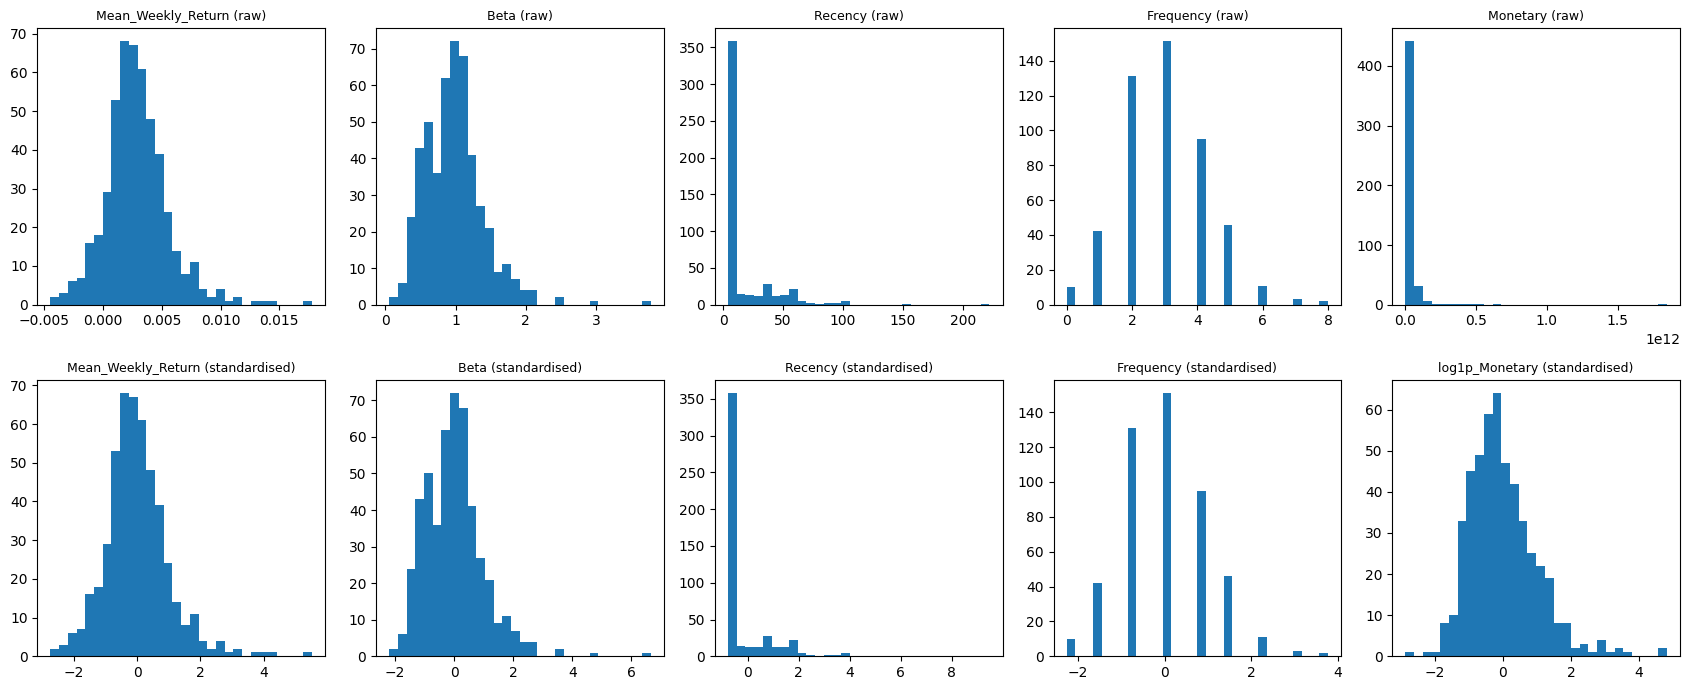

In [ ]:
# Histograms: raw and standardised
fig, axes = plt.subplots(2, 5, figsize=(17, 7))

for i, column in enumerate(raw_cols):
    axes[0, i].hist(features[column], bins=30)
    axes[0, i].set_title(column + " (raw)", fontsize=9)

scaled_columns = list(risk_scaled.columns) + list(activity_scaled.columns)
scaled_data = pd.concat([risk_scaled, activity_scaled], axis=1)

for i, column in enumerate(scaled_columns):
    axes[1, i].hist(scaled_data[column], bins=30)
    axes[1, i].set_title(column + " (standardised)", fontsize=9)

plt.tight_layout()
plt.show()

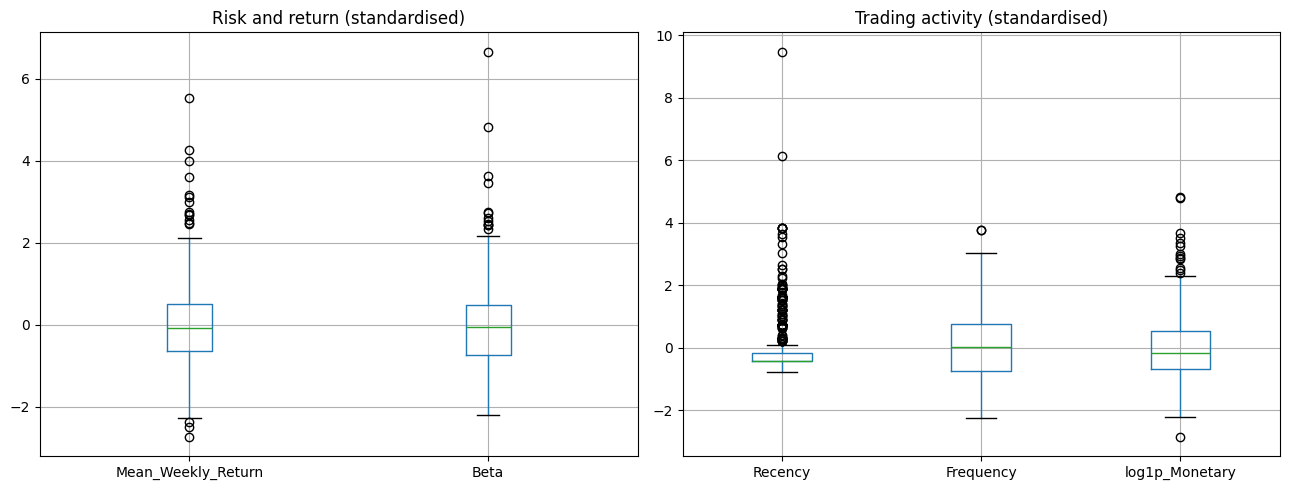

In [ ]:
# Boxplots of standardised features
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

risk_scaled.boxplot(ax=axes[0])
axes[0].set_title("Risk and return (standardised)")

activity_scaled.boxplot(ax=axes[1])
axes[1].set_title("Trading activity (standardised)")

plt.tight_layout()
plt.show()

2.2 — Agglomerative Clustering

In [ ]:
# Maintain variables for subsequent coursework sections
FEATURES = features.rename(columns={
    'Mean_Weekly_Return': 'MeanWeeklyReturn',
    'Beta': 'WeeklyBeta',
    'Recency': 'R',
    'Frequency': 'F',
    'Monetary': 'M'
}).copy()

FEATURES['LogM'] = FEATURES['log1p_Monetary']

X_risk = risk_scaled.to_numpy()
X_rfm = activity_scaled.to_numpy()

ward_results = {}
ward_labels = {}
ward_k = {}

for name, X, columns in [
    ('RiskReturn', X_risk, ['MeanWeeklyReturn', 'WeeklyBeta']),
    ('RFM', X_rfm, ['R', 'F', 'M'])
]:
    results = []

    for k in range(2, 9):
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward',
            metric='euclidean'
        )

        labels = model.fit_predict(X)
        sizes = np.bincount(labels)

        results.append({
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'ClusterSizes': sorted(sizes.tolist()),
            'SmallestCluster': sizes.min()
        })

    ward_results[name] = pd.DataFrame(results)

    print("\nWard Clustering:", name)
    display(ward_results[name].round(3))



Ward Clustering: RiskReturn


,k,Silhouette,ClusterSizes,SmallestCluster
0,2,0.511,"[36, 455]",36
1,3,0.264,"[36, 123, 332]",36
2,4,0.296,"[36, 123, 155, 177]",36
3,5,0.324,"[36, 48, 107, 123, 177]",36
4,6,0.328,"[6, 30, 48, 107, 123, 177]",6
5,7,0.295,"[6, 30, 48, 69, 107, 108, 123]",6
6,8,0.293,"[6, 20, 30, 48, 69, 103, 107, 108]",6



Ward Clustering: RFM


,k,Silhouette,ClusterSizes,SmallestCluster
0,2,0.359,"[92, 399]",92
1,3,0.307,"[92, 147, 252]",92
2,4,0.293,"[43, 92, 147, 209]",43
3,5,0.312,"[10, 43, 82, 147, 209]",10
4,6,0.320,"[10, 20, 43, 82, 127, 209]",10
5,7,0.298,"[10, 20, 43, 66, 82, 127, 143]",10
6,8,0.305,"[10, 20, 43, 57, 66, 70, 82, 143]",10


In [ ]:
# Provisional k using silhouette and cluster size
for name, X in [('RiskReturn', X_risk), ('RFM', X_rfm)]:
    candidates = ward_results[name][
        ward_results[name]['SmallestCluster'] >= 5
    ]

    if candidates.empty:
        candidates = ward_results[name]

    ward_k[name] = int(
        candidates.sort_values(
            'Silhouette', ascending=False
        ).iloc[0]['k']
    )

    ward_labels[name] = AgglomerativeClustering(
        n_clusters=ward_k[name],
        linkage='ward',
        metric='euclidean'
    ).fit_predict(X)

    print(f"{name} - Provisional selected k:", ward_k[name])

RiskReturn - Provisional selected k: 2
RFM - Provisional selected k: 2


In [ ]:
# Original-unit cluster profiles
for name, columns in [
    ('RiskReturn', ['MeanWeeklyReturn', 'WeeklyBeta']),
    ('RFM', ['R', 'F', 'M'])
]:
    print(f"\n=== {name} Cluster Profiles ===")
    profile = FEATURES[columns].copy()
    profile['Cluster'] = ward_labels[name]

    display(
        profile.groupby('Cluster').agg(
            ['mean', 'median', 'count']
        ).round(3)
    )


=== RiskReturn Cluster Profiles ===


MeanWeeklyReturn              WeeklyBeta             
                    mean median count       mean median count
Cluster                                                      
0                  0.002  0.003   455      0.938  0.931   455
1                  0.009  0.008    36      1.519  1.445    36


=== RFM Cluster Profiles ===


R                   F                          M                \
           mean median count   mean median count          mean        median   
Cluster                                                                        
0        12.328   11.0   399  3.211    3.0   399  3.835661e+10  1.548218e+10   
1        55.587   53.0    92  2.054    2.0    92  4.569727e+10  2.048974e+10   

               
        count  
Cluster        
0         399  
1          92

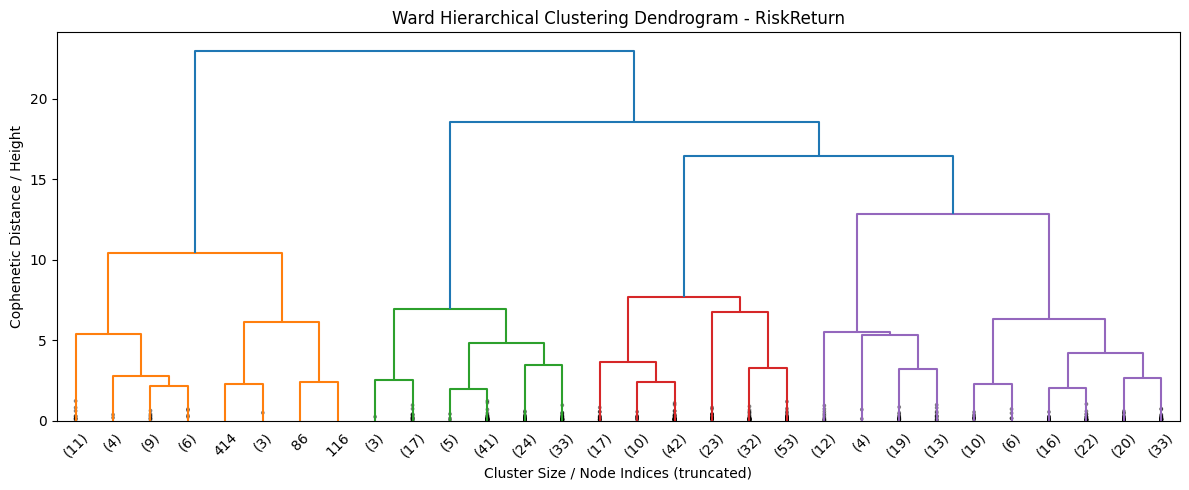

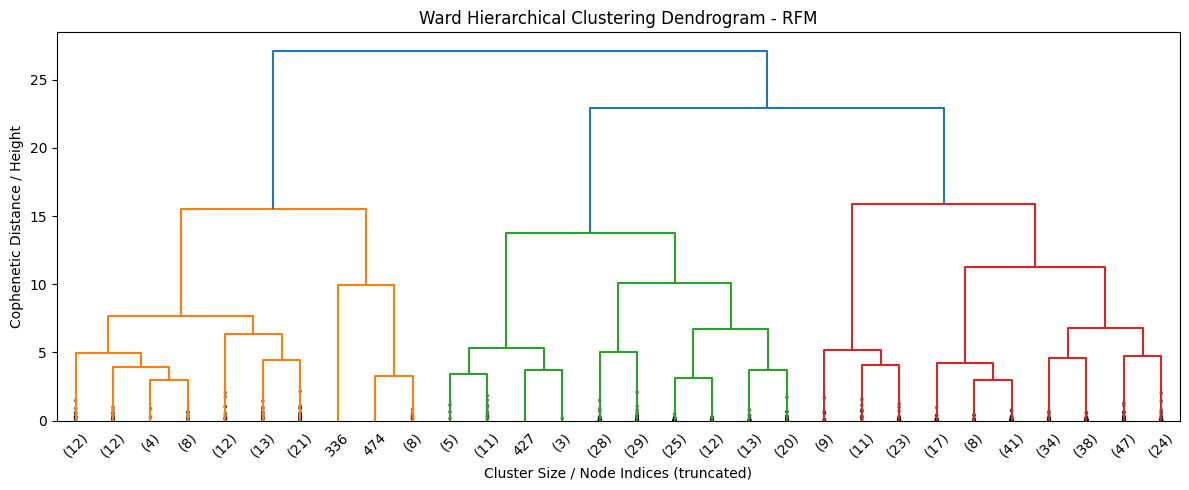

In [ ]:
# Ward dendrogram
for name, X in [('RiskReturn', X_risk), ('RFM', X_rfm)]:
    Z = linkage(X, method='ward', metric='euclidean')

    plt.figure(figsize=(12, 5))
    dendrogram(
        Z,
        truncate_mode='lastp',
        p=30,
        show_contracted=True
    )
    plt.title(f"Ward Hierarchical Clustering Dendrogram - {name}")
    plt.xlabel("Cluster Size / Node Indices (truncated)")
    plt.ylabel("Cophenetic Distance / Height")
    plt.tight_layout()
    plt.show()

2.3 — K-Means Clustering

In [ ]:
kmeans_results = {}
kmeans_labels = {}
kmeans_k = {}

for name, X in [
    ('RiskReturn', X_risk),
    ('RFM', X_rfm)
]:
    results = []

    for k in range(2, 9):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=30
        )

        labels = model.fit_predict(X)
        sizes = np.bincount(labels)

        results.append({
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'Inertia': model.inertia_,
            'ClusterSizes': sorted(sizes.tolist()),
            'SmallestCluster': sizes.min()
        })

    kmeans_results[name] = pd.DataFrame(results)

    print("\nK-Means Clustering:", name)
    display(kmeans_results[name].round(3))

    # Provisional k using silhouette and cluster size
    candidates = kmeans_results[name][
        kmeans_results[name]['SmallestCluster'] >= 5
    ]

    if candidates.empty:
        candidates = kmeans_results[name]

    kmeans_k[name] = int(
        candidates.sort_values(
            'Silhouette', ascending=False
        ).iloc[0]['k']
    )

    kmeans_labels[name] = KMeans(
        n_clusters=kmeans_k[name],
        random_state=42,
        n_init=30
    ).fit_predict(X)

    print("Provisional selected k:", kmeans_k[name])


K-Means Clustering: RiskReturn


,k,Silhouette,Inertia,ClusterSizes,SmallestCluster
0,2,0.389,627.141,"[146, 345]",146
1,3,0.321,473.601,"[121, 166, 204]",121
2,4,0.323,373.915,"[37, 121, 158, 175]",37
3,5,0.309,315.455,"[7, 101, 102, 118, 163]",7
4,6,0.335,260.898,"[7, 43, 50, 105, 127, 159]",7
5,7,0.328,224.911,"[7, 41, 47, 77, 85, 103, 131]",7
6,8,0.355,192.952,"[7, 29, 40, 43, 76, 76, 80, 140]",7


Provisional selected k: 2

K-Means Clustering: RFM


,k,Silhouette,Inertia,ClusterSizes,SmallestCluster
0,2,0.424,1079.102,"[69, 422]",69
1,3,0.325,807.181,"[63, 153, 275]",63
2,4,0.341,616.031,"[61, 93, 122, 215]",61
3,5,0.358,520.538,"[11, 68, 89, 122, 201]",11
4,6,0.346,440.963,"[11, 42, 69, 106, 120, 143]",11
5,7,0.348,391.651,"[1, 15, 42, 64, 106, 119, 144]",1
6,8,0.348,346.357,"[1, 11, 19, 64, 67, 81, 106, 142]",1


Provisional selected k: 2


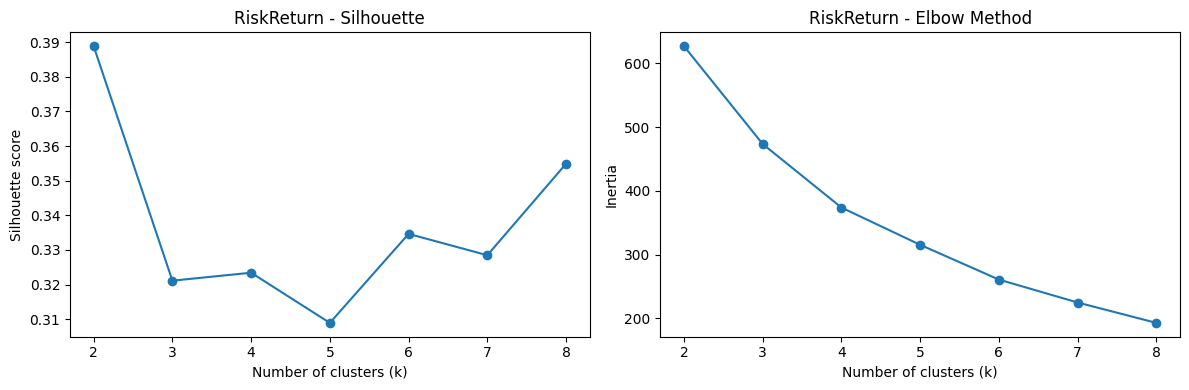

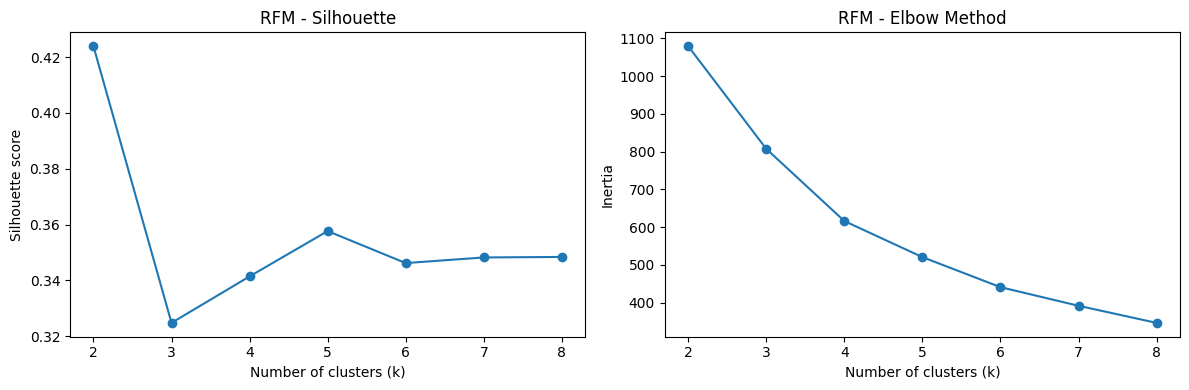

In [ ]:
# Silhouette and inertia plots
for name in ['RiskReturn', 'RFM']:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        kmeans_results[name]['k'],
        kmeans_results[name]['Silhouette'],
        marker='o'
    )
    axes[0].set_title(name + " - Silhouette")
    axes[0].set_xlabel("Number of clusters (k)")
    axes[0].set_ylabel("Silhouette score")

    axes[1].plot(
        kmeans_results[name]['k'],
        kmeans_results[name]['Inertia'],
        marker='o'
    )
    axes[1].set_title(name + " - Elbow Method")
    axes[1].set_xlabel("Number of clusters (k)")
    axes[1].set_ylabel("Inertia")

    plt.tight_layout()
    plt.show()

Task 2.4 — Cluster Profiles and Algorithm Comparison

In [ ]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [ ]:
FEATURES = features.rename(columns={
    'Mean_Weekly_Return': 'MeanWeeklyReturn',
    'Beta': 'WeeklyBeta',
    'Recency': 'R',
    'Frequency': 'F',
    'Monetary': 'M'
}).copy()

FEATURES['LogM'] = FEATURES['log1p_Monetary']

In [ ]:
# Four clustering solutions
MODEL_LABELS = pd.DataFrame({
    'Ward_Risk': ward_labels['RiskReturn'],
    'KMeans_Risk': kmeans_labels['RiskReturn'],
    'Ward_RFM': ward_labels['RFM'],
    'KMeans_RFM': kmeans_labels['RFM']
}, index=FEATURES.index)

DATA = FEATURES.join(MODEL_LABELS)

DATA['MeanWeeklyReturnPct'] = (
    DATA['MeanWeeklyReturn'] * 100
)

In [ ]:
# Original-unit cluster profiles
for solution in MODEL_LABELS.columns:
    print("\nCluster Profile:", solution)

    profile = DATA.groupby(solution).agg(
        Shares=('M', 'size'),
        MeanReturnPct=('MeanWeeklyReturnPct', 'mean'),
        MeanBeta=('WeeklyBeta', 'mean'),
        MeanR=('R', 'mean'),
        MeanF=('F', 'mean'),
        MeanM_USD=('M', 'mean')
    )

    display(profile.round(3))


Cluster Profile: Ward_Risk


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
Ward_Risk,,,,,,
0,455,0.241,0.938,19.835,2.967,3.422715e+10
1,36,0.902,1.519,28.000,3.333,1.093078e+11



Cluster Profile: KMeans_Risk


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
KMeans_Risk,,,,,,
0,345,0.183,0.818,19.458,2.922,2.183804e+10
1,146,0.541,1.366,22.740,3.164,8.201583e+10



Cluster Profile: Ward_RFM


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
Ward_RFM,,,,,,
0,399,0.289,0.974,12.328,3.211,3.835661e+10
1,92,0.293,1.009,55.587,2.054,4.569727e+10



Cluster Profile: KMeans_RFM


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
KMeans_RFM,,,,,,
0,422,0.287,0.976,13.450,3.187,3.271447e+10
1,69,0.308,1.012,63.145,1.812,8.265111e+10


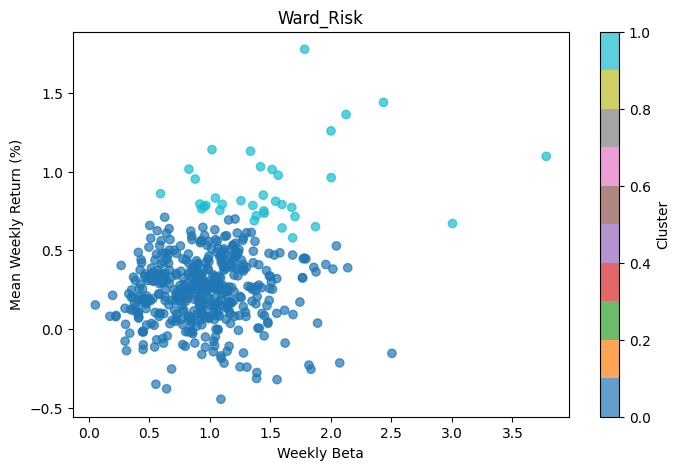

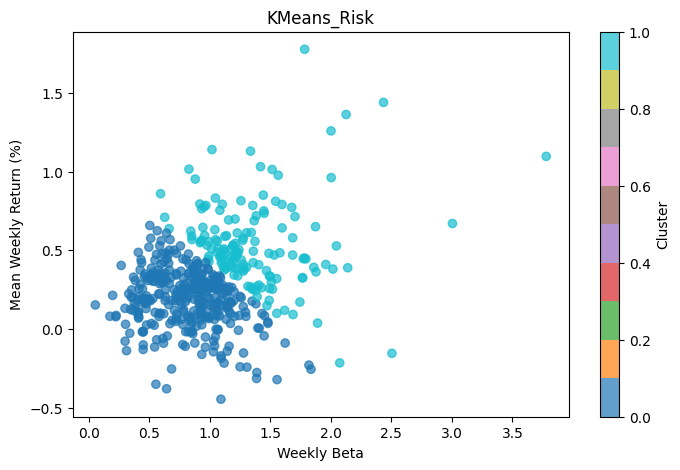

In [ ]:
# Risk-return scatter plots
for solution in ['Ward_Risk', 'KMeans_Risk']:
    plt.figure(figsize=(8, 5))

    scatter = plt.scatter(
        DATA['WeeklyBeta'],
        DATA['MeanWeeklyReturnPct'],
        c=DATA[solution],
        cmap='tab10',
        alpha=0.7
    )

    plt.xlabel('Weekly Beta')
    plt.ylabel('Mean Weekly Return (%)')
    plt.title(solution)
    plt.colorbar(scatter, label='Cluster')
    plt.show()

PCA explained variance: [0.456 0.339]


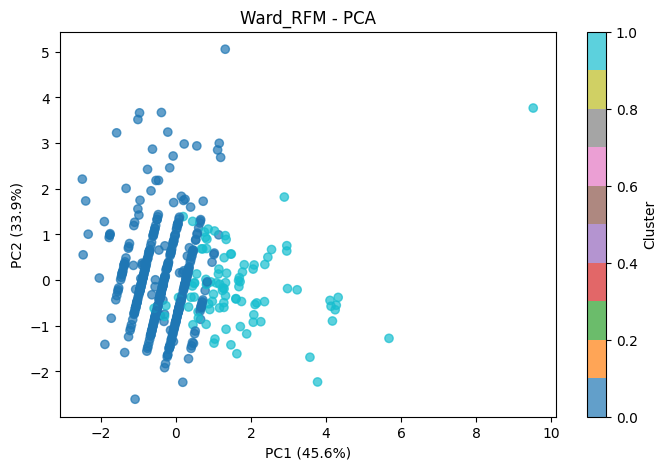

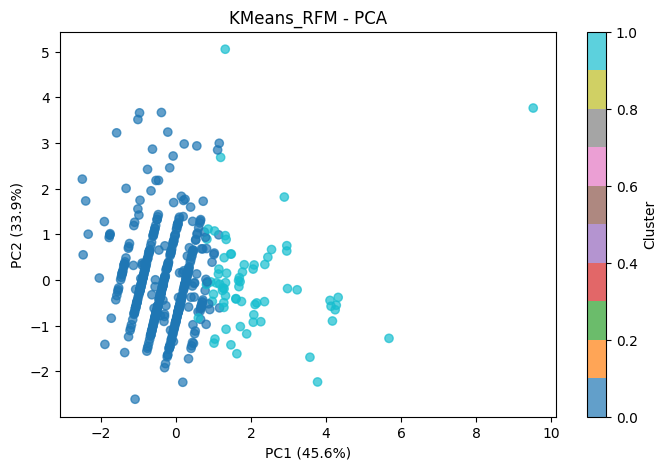

In [ ]:
# RFM PCA visualisation
pca = PCA(n_components=2)
rfm_2d = pca.fit_transform(X_rfm)

print(
    "PCA explained variance:",
    pca.explained_variance_ratio_.round(3)
)

for solution in ['Ward_RFM', 'KMeans_RFM']:
    plt.figure(figsize=(8, 5))

    scatter = plt.scatter(
        rfm_2d[:, 0],
        rfm_2d[:, 1],
        c=DATA[solution],
        cmap='tab10',
        alpha=0.7
    )

    plt.xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"
    )
    plt.ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]:.1%})"
    )
    plt.title(solution + ' - PCA')
    plt.colorbar(scatter, label='Cluster')
    plt.show()


In [ ]:
# Algorithm comparison on identical shares
for name, ward_col, kmeans_col in [
    ('RiskReturn', 'Ward_Risk', 'KMeans_Risk'),
    ('RFM', 'Ward_RFM', 'KMeans_RFM')
]:
    print("\nAlgorithm comparison:", name)

    print(
        "Adjusted Rand Index:",
        round(
            adjusted_rand_score(
                DATA[ward_col], DATA[kmeans_col]
            ), 4
        )
    )

    display(pd.crosstab(
        DATA[ward_col],
        DATA[kmeans_col]
    ))



Algorithm comparison: RiskReturn
Adjusted Rand Index: 0.2097


KMeans_Risk,0,1
Ward_Risk,,
0,345,110
1,0,36



Algorithm comparison: RFM
Adjusted Rand Index: 0.7393


KMeans_RFM,0,1
Ward_RFM,,
0,397,2
1,25,67


Task 2.5 — RFM Sensitivity and Correlated Inputs

Task 2.5.1 — Correlation Analysis

In [ ]:
rfm_correlation = FEATURES[
    ['R', 'F', 'LogM']
].corr(method='pearson')

print("Correlation between R, F and log1p(M):")
display(rfm_correlation.round(3))


Correlation between R, F and log1p(M):


,R,F,LogM
R,1.000,-0.342,0.159
F,-0.342,1.000,0.022
LogM,0.159,0.022,1.000


Task 2.5.2 — Removal of Monetary

In [ ]:
# Re-standardise Recency and Frequency
X_rf = StandardScaler().fit_transform(
    FEATURES[['R', 'F']]
)

In [ ]:
# Use the same number of Ward RFM clusters
k = ward_k['RFM']

rf_without_m = AgglomerativeClustering(
    n_clusters=k,
    linkage='ward',
    metric='euclidean'
).fit_predict(X_rf)

In [ ]:
# Adjusted Rand Index
ari = adjusted_rand_score(
    MODEL_LABELS['Ward_RFM'],
    rf_without_m
)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.9523


In [ ]:
# Cluster membership comparison
comparison = pd.crosstab(
    MODEL_LABELS['Ward_RFM'],
    rf_without_m,
    rownames=['Original RFM Cluster'],
    colnames=['RF Cluster Without M']
)

print("Cluster Membership Comparison:")
display(comparison)

Cluster Membership Comparison:


RF Cluster Without M,0,1
Original RFM Cluster,,
0,397,2
1,3,89


In [ ]:
# Compare original and reduced cluster profiles
comparison_data = FEATURES[['R', 'F', 'M']].copy()

comparison_data['Original_RFM'] = (
    MODEL_LABELS['Ward_RFM']
)

comparison_data['Without_M'] = rf_without_m

for solution in ['Original_RFM', 'Without_M']:
    print("\nCluster Profile:", solution)

    profile = comparison_data.groupby(solution).agg(
        Shares=('M', 'size'),
        MeanR=('R', 'mean'),
        MeanF=('F', 'mean'),
        MeanM_USD=('M', 'mean'),
        MedianM_USD=('M', 'median')
    )

    display(profile.round(3))



Cluster Profile: Original_RFM


,Shares,MeanR,MeanF,MeanM_USD,MedianM_USD
Original_RFM,,,,,
0,399,12.328,3.211,3.835661e+10,1.548218e+10
1,92,55.587,2.054,4.569727e+10,2.048974e+10



Cluster Profile: Without_M


,Shares,MeanR,MeanF,MeanM_USD,MedianM_USD
Without_M,,,,,
0,400,12.320,3.212,3.782930e+10,1.546039e+10
1,91,56.099,2.033,4.809577e+10,2.084781e+10
